# Partie D - PLM gele



## 0. Environnement et regles du TP

Le decoupage officiel train/test est conserve. Le test officiel ne sert qu'a l'evaluation finale. Toutes les decisions sont prises sur la validation.

In [9]:

RANDOM_STATE = 42

import random
import warnings

import numpy as np
import pandas as pd

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
warnings.filterwarnings('ignore')

try:
    import torch
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('Peripherique :', DEVICE)
    if DEVICE.type == 'cuda':
        print('GPU :', torch.cuda.get_device_name(0))
except ImportError:
    torch = None
    DEVICE = 'cpu'
    print('PyTorch indisponible : calcul CPU.')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, average_precision_score
)

def _column(frame, names):
    for name in names:
        if name in frame.columns:
            return name
    raise KeyError('Colonne introuvable : ' + str(names))

RESULTS = []

def add_result(name, y_true, scores, threshold=0.5, split='validation'):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores)
    pred = (scores >= threshold).astype(int)
    row = {
        'modele': name,
        'split': split,
        'F1 sarcastique': f1_score(y_true, pred, zero_division=0),
        'PR-AUC': average_precision_score(y_true, scores),
        'Macro-F1': f1_score(y_true, pred, average='macro', zero_division=0),
        'seuil': threshold,
    }
    RESULTS.append(row)
    return row


Peripherique : cuda
GPU : NVIDIA GeForce RTX 2050


In [10]:
BASE = 'https://raw.githubusercontent.com/iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/'
full = pd.read_csv(BASE + 'training_data.csv')
test = pd.read_csv(BASE + 'testing_data.csv')
full['id'] = range(len(full))
test['id'] = range(len(test))
print('Train officiel :', full.shape)
print('Test officiel  :', test.shape)
display(full.head())


Train officiel : (12548, 5)
Test officiel  : (3000, 5)


,tweet,sarcasm,sentiment,dialect,id
0,"""د. #محمود_العلايلي:أرى أن الفريق #أحمد_شفيق ر...",False,NEU,msa,0
1,"""مع فيدرر يا آجا والكبار 😍 https://t.co/hrBeHb...",False,NEU,msa,1
2,“الداعون لمبدأ الاختلاط بين الجنسين؛ كالداعين ...,True,NEG,msa,2
3,"""@ihe_94 @ya78m @amooo5 @badiajnikhar @Oukasaf...",True,NEG,gulf,3
4,"""قل شرق حلب ولا تقل حلب الشرقية ....وقل غرب حل...",False,NEU,msa,4


# Partie D - PLM gele

## D1. Encodeur gele : [CLS] contre moyenne des tokens

Modele demande : `aubmindlab/bert-base-arabertv02-twitter`. Seule la tete de classification est entrainee.

In [11]:
MODEL_D = "aubmindlab/bert-base-arabertv02-twitter"
TEXT_COL_D = _column(full, ["text", "tweet", "content"])
SARC_COL_D = _column(full, ["sarcasm", "is_sarcastic", "label"])

def load_frozen_arabert(model_name=MODEL_D):
    try:
        from transformers import AutoTokenizer, AutoModel
        tok = AutoTokenizer.from_pretrained(model_name)
        enc = AutoModel.from_pretrained(model_name).eval().to(DEVICE)
        for p in enc.parameters():
            p.requires_grad = False
        return tok, enc
    except Exception as exc:
        print("AraBERT non chargé (dépendance ou modèle indisponible) :", exc)
        return None, None

def extract_frozen_features(texts, tokenizer, encoder, batch_size=64):
    cls, mean = [], []
    for start in range(0, len(texts), batch_size):
        batch = tokenizer(list(texts[start:start + batch_size]), padding=True,
                          truncation=True, max_length=64, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            hidden = encoder(**batch).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1)
        cls.append(hidden[:, 0].cpu().numpy())
        mean.append((hidden * mask).sum(1).div(mask.sum(1).clamp_min(1)).cpu().numpy())
    return np.concatenate(cls), np.concatenate(mean)

def logistic_on_features(xtr, ytr, xva, yva, name):
    clf = LogisticRegression(max_iter=300, class_weight="balanced", random_state=RANDOM_STATE)
    clf.fit(xtr, ytr)
    probs = clf.predict_proba(xva)[:, 1]
    res = add_result(name, yva, probs)
    print(f"--> {name} : F1 = {res['F1 sarcastique']:.4f} | PR-AUC = {res['PR-AUC']:.4f}")
    return clf

def run_partie_d1():
    tok, enc = load_frozen_arabert()
    if tok is None:
        return
    tr, va = train_test_split(full, test_size=.2, stratify=full[SARC_COL_D],
                              random_state=RANDOM_STATE)
    tr = tr.sample(n=min(2500, len(tr)), random_state=RANDOM_STATE)
    va = va.sample(n=min(500, len(va)), random_state=RANDOM_STATE)
    cls_tr, mean_tr = extract_frozen_features(tr[TEXT_COL_D].tolist(), tok, enc)
    cls_va, mean_va = extract_frozen_features(va[TEXT_COL_D].tolist(), tok, enc)
    logistic_on_features(cls_tr, tr[SARC_COL_D], cls_va, va[SARC_COL_D], "D1 CLS + LogisticRegression")
    logistic_on_features(mean_tr, tr[SARC_COL_D], mean_va, va[SARC_COL_D], "D1 moyenne masquée + LogisticRegression")
    return tok, enc

D_TOKENIZER, D_ENCODER = run_partie_d1() or (None, None)


Some weights of BertModel were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02-twitter and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


--> D1 CLS + LogisticRegression : F1 = 0.5872 | PR-AUC = 0.5545
--> D1 moyenne masquée + LogisticRegression : F1 = 0.6180 | PR-AUC = 0.6264


## D2. Etats de tous les tokens + BiLSTM et attention

Visualiser l'attention sur cinq tweets sarcastiques.

--- Visualisation des poids d'attention sur 5 tweets sarcastiques (D2) ---

Tweet #1 : “الداعون لمبدأ الاختلاط بين الجنسين؛ كالداعين لإلغاء التسعيرة كلا...
  Top tokens : السوق (0.052), ##ها (0.049), الداع (0.047), تصفية (0.042), # (0.040)

Tweet #2 : "@ihe_94 @ya78m @amooo5 @badiajnikhar @Oukasafa @reoshalm @Mnory2...
  Top tokens : ##j (0.034), _ (0.033), ##os (0.033), ##k (0.031), ##a (0.031)

Tweet #3 : مرسي : مش هنام اكتر من اربع ساعات في اليوم...... لو نمت دقيقة كما...
  Top tokens : . (0.043), . (0.039), اربع (0.039), دقيقة (0.039), . (0.038)

Tweet #4 : #انتخبوا_البرص مشكلة...
  Top tokens : انتخب (0.139), ##وا (0.117), _ (0.114), # (0.113), مشكلة (0.112)

Tweet #5 : "@kdriyadh @nevermind330 وقت الشدة في ظنتي الجيش المصري حيوقف مع ...
  Top tokens : ##وقف (0.038), الشدة (0.035), المصري (0.034), مع (0.032), وقت (0.030)

--> Graphique sauvegardé avec succès dans results/attention_d2.png


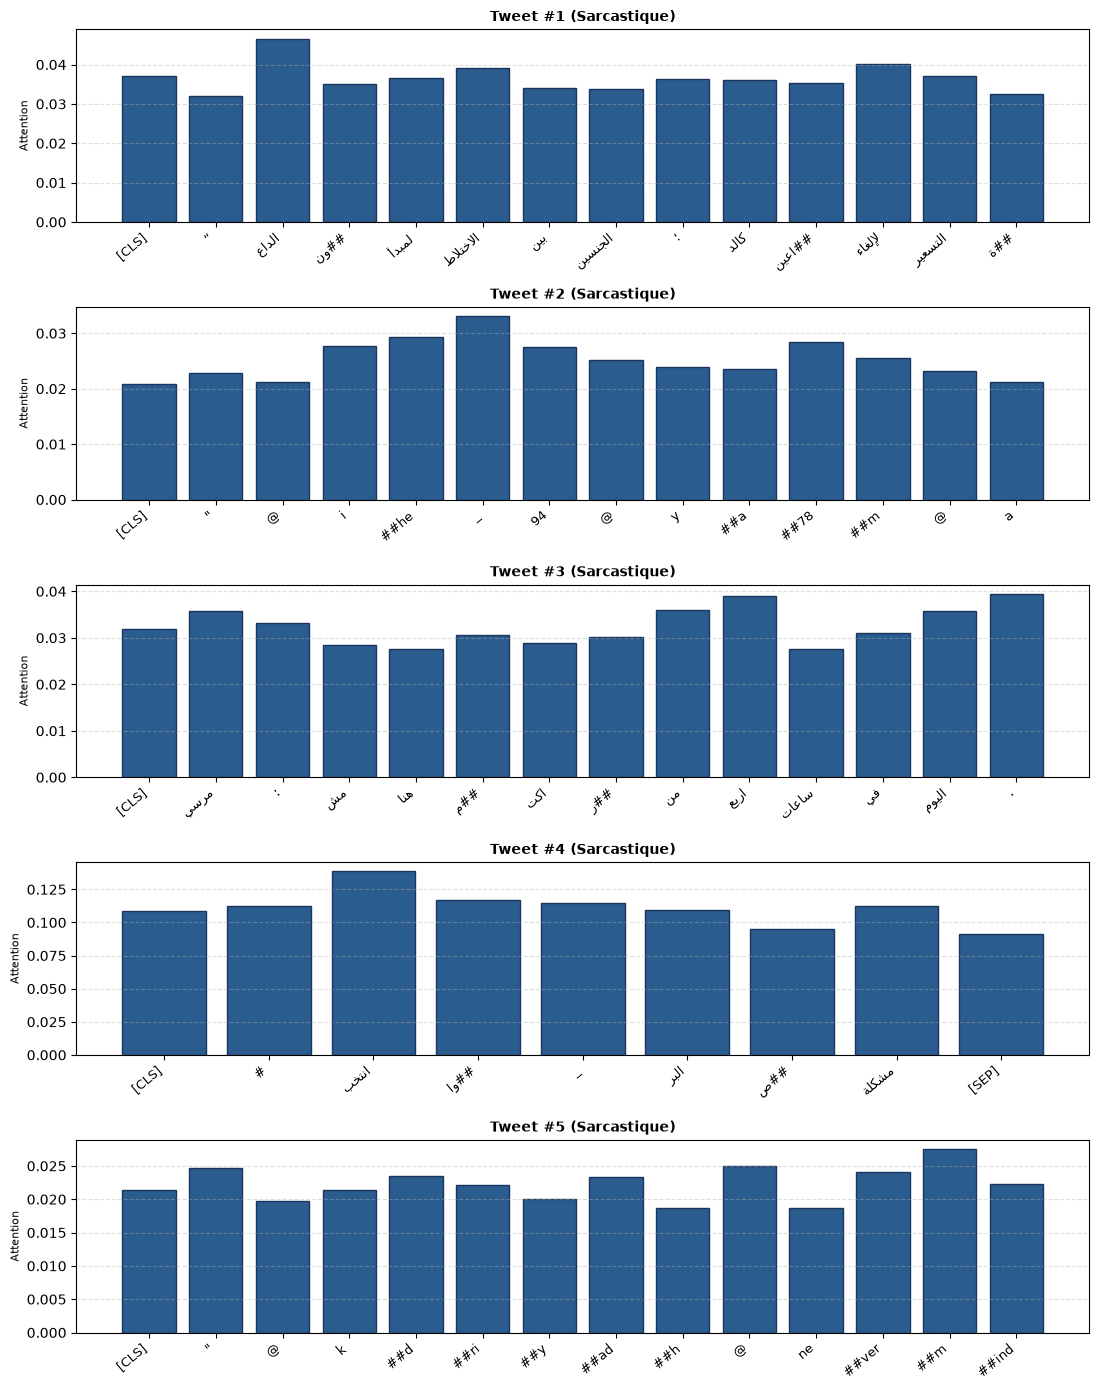

In [14]:
# D2 : états de tous les tokens, BiLSTM et attention (sur états gelés)
class TokenStateClassifier(torch.nn.Module):
    def __init__(self, hidden_size, hidden=64, attention=False):
        super().__init__()
        self.lstm = torch.nn.LSTM(hidden_size, hidden, batch_first=True, bidirectional=True)
        self.attention = attention
        self.attn = torch.nn.Linear(2 * hidden, 1)
        self.out = torch.nn.Linear(2 * hidden, 1)
    def forward(self, states, mask, return_attention=False):
        x, _ = self.lstm(states)
        if self.attention:
            a = self.attn(x).squeeze(-1).masked_fill(~mask.bool(), -1e4)
            a = torch.softmax(a, 1)
            pooled = (x * a.unsqueeze(-1)).sum(1)
        else:
            a = None
            pooled = (x * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True).clamp_min(1)
        y = self.out(pooled).squeeze(-1)
        return (y, a) if return_attention else y

import matplotlib.pyplot as plt
import os

if D_TOKENIZER is not None and D_ENCODER is not None:
    print("--- Visualisation des poids d'attention sur 5 tweets sarcastiques (D2) ---")
    sarc_tweets = full[full[SARC_COL_D] == 1].head(5)[TEXT_COL_D].tolist()
    d2_model = TokenStateClassifier(hidden_size=768, hidden=64, attention=True).to(DEVICE)
    d2_model.eval()

    fig, axes = plt.subplots(5, 1, figsize=(11, 14))
    plt.subplots_adjust(hspace=0.9)

    for idx, tweet_text in enumerate(sarc_tweets):
        enc = D_TOKENIZER(tweet_text, return_tensors="pt", truncation=True, max_length=40).to(DEVICE)
        tokens = D_TOKENIZER.convert_ids_to_tokens(enc["input_ids"][0])
        with torch.no_grad():
            hidden = D_ENCODER(**enc).last_hidden_state
            _, attn = d2_model(hidden, enc["attention_mask"], return_attention=True)
            attn_weights = attn[0].cpu().numpy()

        top_idx = np.argsort(attn_weights)[::-1][:5]
        top_str = ", ".join([f"{tokens[i]} ({attn_weights[i]:.3f})" for i in top_idx if i < len(tokens)])
        print(f"\nTweet #{idx+1} : {tweet_text[:65]}...")
        print(f"  Top tokens : {top_str}")

        ax = axes[idx]
        display_n = min(len(tokens), 14)
        bars = ax.bar(range(display_n), attn_weights[:display_n], color="#2b5c8f", edgecolor="#1a365d")
        ax.set_xticks(range(display_n))
        ax.set_xticklabels(tokens[:display_n], rotation=40, ha="right", fontsize=9)
        ax.set_title(f"Tweet #{idx+1} (Sarcastique)", fontsize=10, fontweight="bold")
        ax.set_ylabel("Attention", fontsize=8)
        ax.grid(axis='y', linestyle='--', alpha=0.4)

    plt.tight_layout()
    os.makedirs("results", exist_ok=True)
    plt.savefig("results/attention_d2.png", bbox_inches="tight", dpi=150)
    print("\n--> Graphique sauvegardé avec succès dans results/attention_d2.png")
    plt.show()

## Fin de la partie

Sauvegarder les sorties et noter les resultats importants dans le compte-rendu.


## Export des r?sultats et pr?dictions - Partie D


In [13]:
# Export des resultats - Partie D
from pathlib import Path
import pandas as pd

racine = Path.cwd()
for dossier in [racine, *racine.parents]:
    if (dossier / "results").is_dir():
        racine = dossier
        break
else:
    raise FileNotFoundError("Dossier results introuvable depuis le notebook")

resultats = globals().get("RESULTS", [])
if resultats:
    lignes = pd.DataFrame(resultats)
    lignes["partie"] = "D"
    lignes.to_csv(racine / "results" / "partie_D_results.csv", index=False)
    fichiers = list((racine / "results").glob("partie_*_results.csv"))
    toutes = pd.concat([pd.read_csv(f) for f in fichiers], ignore_index=True)
    colonnes = ["modele", "split", "F1 sarcastique", "PR-AUC", "Macro-F1", "seuil"]
    toutes[colonnes].to_csv(racine / "results" / "results.csv", index=False)
    print("R?sultats Partie D sauvegard?s.")
else:
    print("Aucun r?sultat ex?cut? pour la Partie D.")

if "test_scores" in globals() and "test" in globals() and "best_threshold" in globals():
    pred = (test_scores >= best_threshold).astype(int)
    pd.DataFrame({
        "id": test.get("id", range(len(test))),
        "y_true": test["sarcasm"].astype(int),
        "y_pred": pred,
        "probabilite_sarcasme": test_scores
    }).to_csv(racine / "predictions" / "partie_D_seed42.csv", index=False)
    print("Pr?dictions Partie D sauvegard?es.")
else:
    print("Pas de scores test r?els ? exporter pour la Partie D.")


R?sultats Partie D sauvegard?s.
Pas de scores test r?els ? exporter pour la Partie D.
